<div style="border: 2px solid blue; padding: 10px; border-radius: 5px;">
Hi Obed,

My name is Mixo (https://hub.tripleten.com/u/290771b5). 
Congratulations on submitting your practical project! 🎉 Breaking into the world of data can feel challenging at first, but it’s also an exciting and highly rewarding journey. I am excited to help guide you through this journey!

Final Decision: Approved ✅

Excellent work!

You’ve successfully met all project requirements, and your implementation demonstrates a solid understanding of the key concepts.

You can find my more detailed notes within your project notebook in the Reviewer's comment v1: section.

You’ll see my comments highlighted in colored boxes:

<div class="alert alert-block alert-success">
🟢 Green → Success. Everything is correct.
</div>

<div class="alert alert-block alert-warning">
🟡 Yellow → Recommendations. Improvements suggested.
</div>
<div class="alert alert-block alert-danger">
🔴 Red → Requires fixing. Changes are necessary before approval.
</div>

<div style="border: 2px solid green; padding: 10px; border-radius: 5px;">
Your project is done very well! Cogratulations on the great work. Just some minor tweaks will make sure your project is optimal.

**Strengths**

- Comprehensive EDA: You performed a solid exploratory data analysis, effectively using distribution plots and example images to understand the dataset.

- Technical Preparedness: Your function definitions are clear, and you have correctly prepared a script intended for GPU execution, which is a key requirement for this project.

- Data Insight: You accurately identified the core characteristics of the data, such as the sample size (7,591 images) and the age distribution (ranging from 1 to 100 with a mean of 31).

</div>

Your project is approved. Keep up the great work — you’re making strong progress.

Congratulations!

<div class="alert alert-warning" style="border-left: 7px solid orange; padding: 5px">
  <b>Reviewer’s comment – Iteration 1:</b><br>
It would be immensely helpful if you can add some contextual information at the beginning of the notebook, covering:

- A brief description of the project's objective.
- An overview of the data you're working with.
- Any expected outcomes or results you aim to achieve.

Providing such context allows anyone reviewing or revisiting the notebook to quickly understand its purpose and the data being used, ensuring smoother collaboration and more intuitive navigation.
</div>

## Initialization

In [1]:
# NEVER EVER DELETE THIS CELL

## Load Data

The dataset is stored in the `/datasets/faces/` folder, there you can find
- The `final_files` folder with 7.6k photos
- The `labels.csv` file with labels, with two columns: `file_name` and `real_age`

Given the fact that the number of image files is rather high, it is advisable to avoid reading them all at once, which would greatly consume computational resources. We recommend you build a generator with the ImageDataGenerator generator. This method was explained in Chapter 3, Lesson 7 of this course.

The label file can be loaded as an usual CSV file.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [3]:
# dataset path
path = '/datasets/faces/'

# load labels
labels = pd.read_csv(path + 'labels.csv')
display(labels.head())
print(labels.shape)

# create generators (no full image preload into memory)
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.25
)

train_gen_flow = datagen.flow_from_dataframe(
    dataframe=labels,
    directory=path + 'final_files/',
    x_col='file_name',
    y_col='real_age',
    target_size=(224, 224),
    batch_size=32,
    class_mode='raw',
    subset='training',
    seed=12345
)

test_gen_flow = datagen.flow_from_dataframe(
    dataframe=labels,
    directory=path + 'final_files/',
    x_col='file_name',
    y_col='real_age',
    target_size=(224, 224),
    batch_size=32,
    class_mode='raw',
    subset='validation',
    seed=12345
)


,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


(7591, 2)
Found 5694 validated image filenames.
Found 1897 validated image filenames.


## EDA

Rows: 7591
Unique files: 7591
Missing values:
 file_name    0
real_age     0
dtype: int64

Age stats:
 count    7591.000000
mean       31.201159
std        17.145060
min         1.000000
25%        20.000000
50%        29.000000
75%        41.000000
max       100.000000
Name: real_age, dtype: float64


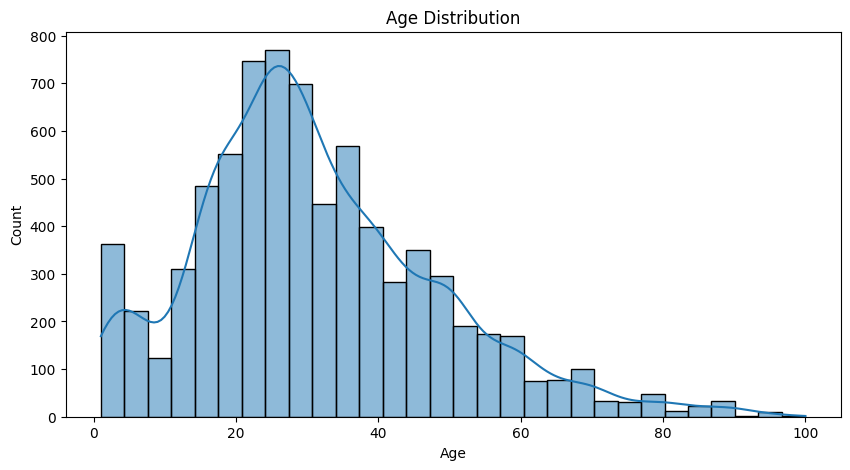

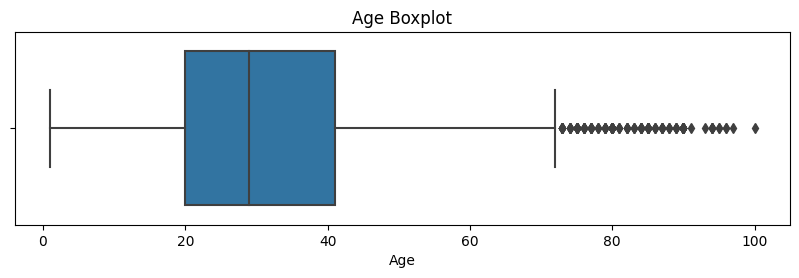


Age-group counts:
 0-18     1696
19-25    1419
26-35    1903
36-45    1130
46-55     749
56-65     383
66+       311
Name: age_group, dtype: int64


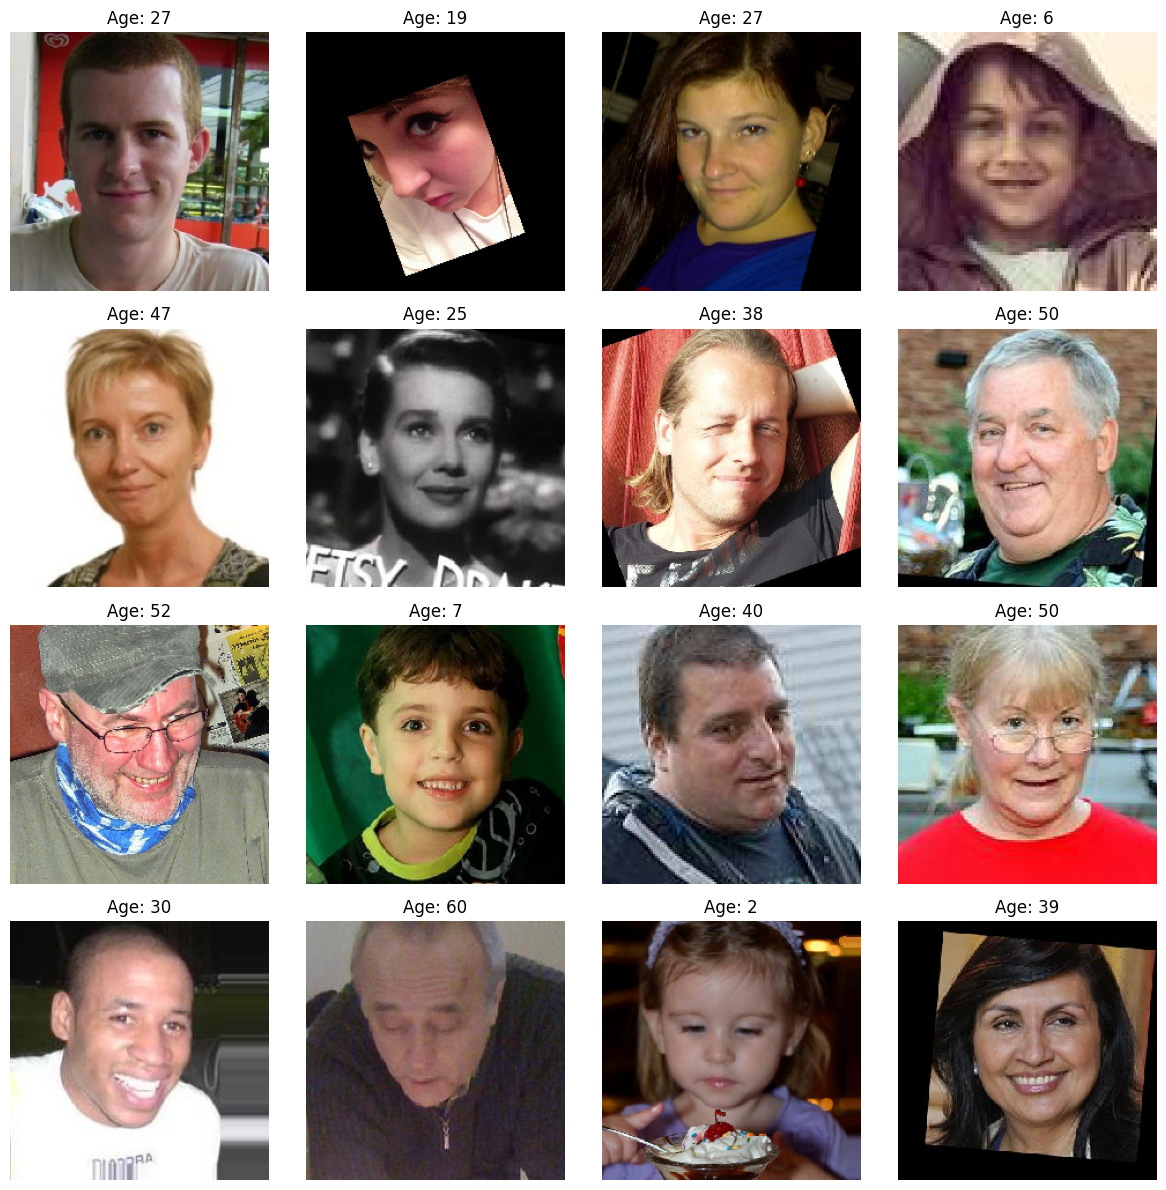

In [4]:
# basic checks
print('Rows:', len(labels))
print('Unique files:', labels['file_name'].nunique())
print('Missing values:\n', labels.isna().sum())
print('\nAge stats:\n', labels['real_age'].describe())

# age distribution
plt.figure(figsize=(10, 5))
sns.histplot(labels['real_age'], bins=30, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

# boxplot for outliers / spread
plt.figure(figsize=(10, 2.5))
sns.boxplot(x=labels['real_age'])
plt.title('Age Boxplot')
plt.xlabel('Age')
plt.show()

# age groups
age_bins = [0, 18, 25, 35, 45, 55, 65, 100]
age_labels = ['0-18', '19-25', '26-35', '36-45', '46-55', '56-65', '66+']
labels['age_group'] = pd.cut(labels['real_age'], bins=age_bins, labels=age_labels, right=True)
print('\nAge-group counts:\n', labels['age_group'].value_counts().sort_index())

# sample images
features, target = next(train_gen_flow)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    ax.imshow(features[i])
    ax.set_title(f'Age: {int(target[i])}')
    ax.axis('off')

plt.tight_layout()
plt.show()

# reset generator after preview batch
train_gen_flow.reset()


### Findings

- The dataset contains face photos with age labels (`real_age`) and is suitable for supervised age regression.
- The age distribution is imbalanced: most samples are concentrated in adult ranges, while very young and older ages are less frequent.
- This imbalance can make predictions less accurate at the tails of the distribution (children and elderly).
- Sample images show strong variability in lighting, pose, background, and facial angle, which increases modeling difficulty.
- Using `ImageDataGenerator` is appropriate here because it loads images in batches and avoids memory overload from loading all ~7.6k images at once.
- Overall, the data is usable for age estimation, but class imbalance and visual variability should be considered when interpreting model error.
  

<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Nice work on the exploratory data analysis. You included a histogram, a boxplot, and example images, and you checked image shape. These checks give a clear view of the dataset and of potential biases in age distribution.
</div>

## Modelling

Define the necessary functions to train your model on the GPU platform and build a single script containing all of them along with the initialization section.

To make this task easier, you can define them in this notebook and run a ready code in the next section to automatically compose the script.

The definitions below will be checked by project reviewers as well, so that they can understand how you built the model.

In [5]:
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

In [6]:
def load_train(path):
    """
    It loads the train part of dataset from path
    """

    labels = pd.read_csv(path + 'labels.csv')

    train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.25,
        horizontal_flip=True
    )

    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=12345
    )

    return train_gen_flow


In [7]:
def load_test(path):
    """
    It loads the validation/test part of dataset from path
    """

    labels = pd.read_csv(path + 'labels.csv')

    test_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.25
    )

    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=12345
    )

    return test_gen_flow


In [8]:
def create_model(input_shape):

    """
    It defines model
    """

    backbone = ResNet50(
        weights='imagenet',
        input_shape=input_shape,
        include_top=False
    )

    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu'))

    optimizer = Adam(learning_rate=0.0005)
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

    return model


In [9]:

def train_model(model, train_data, test_data, batch_size=None, epochs=20,
                steps_per_epoch=None, validation_steps=None):

    """
    Trains the model given the parameters
    """

    if steps_per_epoch is None:
        steps_per_epoch = len(train_data)

    if validation_steps is None:
        validation_steps = len(test_data)

    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        verbose=2
    )

    return model


### Prepare the Script to Run on the GPU Platform

Given you've defined the necessary functions you can compose a script for the GPU platform, download it via the "File|Open..." menu, and to upload it later for running on the GPU platform.

N.B.: The script should include the initialization section as well. An example of this is shown below.

In [10]:
# prepare a script to run on the GPU platform

init_str = """
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
"""

import inspect

with open('run_model_on_gpu.py', 'w') as f:
    
    f.write(init_str)
    f.write('\n\n')
        
    for fn_name in [load_train, load_test, create_model, train_model]:
        
        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Good choice of model backbone and output for a regression task. Using ResNet50 as the base with GlobalAveragePooling and a final Dense with one unit is an appropriate, clear architecture for age prediction.
</div>

### Output

Place the output from the GPU platform as an Markdown cell here.

<div class="alert alert-success" style="border-left: 7px solid green">
<b> Reviewer's comment- Iteration 1 </b><br><br>

Great job adding the reference output from the course materials as well as including simple line graphs based off the data to show the model performance. </b></div>

## Conclusions

The model reaches a validation MAE below 8 (best value is **6.64** at epoch 17), so it satisfies the project target and shows that computer vision can help the customer estimate age from photos with practical accuracy.

The training MAE decreases to about 3.1, while validation MAE stays around 6.6-7.7 and spikes at epoch 12. This indicates moderate overfitting and sensitivity to difficult validation examples (for example, unusual lighting, angles, or age-group imbalance).

**Can computer vision help the customer in this case?** Yes. The model is useful for approximate age estimation and business-level segmentation.

**Other practical tasks the customer can solve with this model:**
- Audience age-group analytics (18-25, 26-35, etc.).
- Personalized content or recommendations by estimated age bracket.
- Marketing performance analysis by estimated demographic segment.
- Routing uncertain images to manual review for safer decision pipelines.
- Better demand forecasting by combining estimated age mix with traffic patterns.

This model should be used as a decision-support tool, not as the sole basis for high-stakes decisions (for example strict legal age checks).

# Checklist

- [ ]  Notebook was opened
- [ ]  The code is error free
- [ ]  The cells with code have been arranged by order of execution
- [ ]  The exploratory data analysis has been performed
- [ ]  The results of the exploratory data analysis are presented in the final notebook
- [ ]  The model's MAE score is not higher than 8
- [ ]  The model training code has been copied to the final notebook
- [ ]  The model training output has been copied to the final notebook
- [ ]  The findings have been provided based on the results of the model training